# 03 — Joint Energy-based Model

**Objectif** : apprendre, dans le même réseau, la priorité p(y | x) **et** la plausibilité p(x) d'un bug, pour disposer d'un signal d'atypicité que le classifieur n'a pas.

**Principaux résultats**

- L'énergie implicite d'un classifieur est **inversée** : elle est minimale loin des données, en 2D comme sur les vrais bugs (bots détectés avec une AUROC de 0,27, pire que le hasard).
- Entraîné en JEM, le même réseau retrouve un paysage d'énergie cohérent : basse sur les données, haute ailleurs, sans perte d'accuracy.
- `alpha` (poids du terme génératif) est choisi sur la **validation 2025** : `alpha = 1` donne la meilleure détection des bots de 2025 (0,77) et une NLL de validation légèrement meilleure que le classifieur (1,127 contre 1,134).
- Coût : ~13 fois plus de temps par époque (20 pas de Langevin par lot), et une détection qui fluctue d'une époque à l'autre.

Référence : Grathwohl et al., *Your classifier is secretly an energy based model and you should treat it like one*, ICLR 2020.

In [1]:
import logging
import os
import warnings
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")  # chemins relatifs à la racine du projet (data/, mlflow.db)

warnings.filterwarnings("ignore")
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd

from jem_prioriser.plotstyle import CLASS_COLORS, HUMAN_BOT_COLORS, MODEL_COLORS, SERIES, use_style

logging.getLogger("mlflow").setLevel(logging.ERROR)
use_style()
pd.set_option("display.max_colwidth", 90)

## 1. L'énergie cachée dans un classifieur

Un classifieur produit des logits f(x) ; le softmax n'en retient que les écarts. Leur niveau global définit une énergie :

$$E(x) = -\log \sum_y e^{f(x)_y}, \qquad p(x) \propto e^{-E(x)}, \qquad p(y \mid x) = \mathrm{softmax}(f(x))_y$$

Cette lecture ne change rien à p(y | x). Mais rien, dans l'entropie croisée, ne contraint E(x). Illustration sur trois nuages de points en 2D, avec le même `MLP` et la même fonction de perte que sur les bugs :

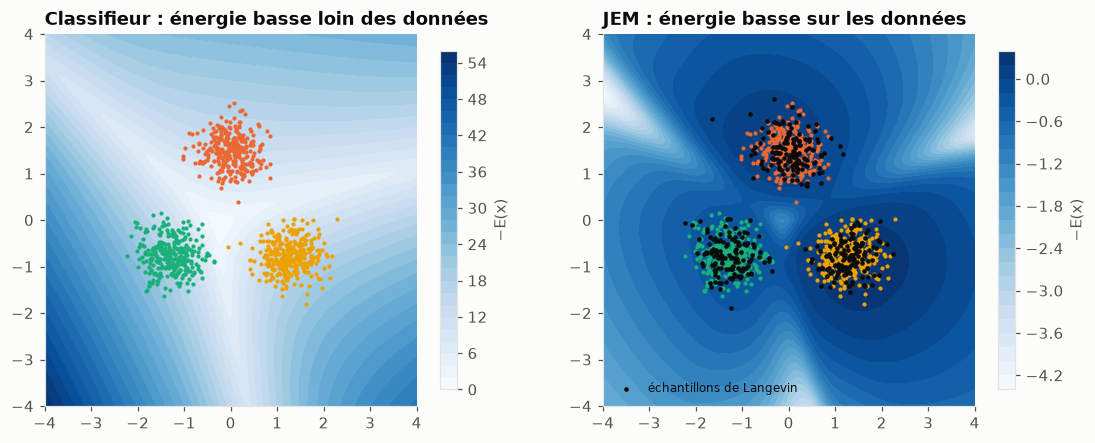

accuracy : classifieur 1.000 | JEM 1.000


In [2]:
import torch
from jem_prioriser import toy
from jem_prioriser.model import sgld

x_toy, y_toy = toy.make_toy()
clf_toy, _ = toy.train_toy(x_toy, y_toy, alpha=0)
jem_toy, buf_toy = toy.train_toy(x_toy, y_toy, alpha=1)

def plot_landscape(ax, model, title, samples=None):
    xx, yy, e = toy.energy_grid(model)
    cs = ax.contourf(xx, yy, -e, levels=30, cmap="Blues")
    plt.colorbar(cs, ax=ax, shrink=0.8, label="−E(x)")
    for k in range(3):
        pts = x_toy[y_toy == k]
        ax.scatter(pts[:, 0], pts[:, 1], s=3, color=SERIES[1:4][k])
    if samples is not None:
        ax.scatter(samples[:, 0], samples[:, 1], s=4, color="#0b0b0b", label="échantillons de Langevin")
        ax.legend(loc="lower left", fontsize=8)
    ax.set_title(title); ax.set_aspect("equal"); ax.grid(False)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_landscape(axes[0], clf_toy, "Classifieur : énergie basse loin des données")
plot_landscape(axes[1], jem_toy, "JEM : énergie basse sur les données", buf_toy.buffer.numpy()[:400])
plt.show()
acc = lambda m: (m(torch.from_numpy(x_toy)).argmax(1).numpy() == y_toy).mean()
print(f"accuracy : classifieur {acc(clf_toy):.3f} | JEM {acc(jem_toy):.3f}")

Pour séparer les classes, le classifieur fait croître ses logits en s'éloignant des frontières, y compris au-delà des données : loin de tout, il est à la fois très confiant et d'énergie très basse. Même constat sur les vrais bugs, avec le MLP du notebook 02 :

In [3]:
from jem_prioriser.metrics import ood_auroc
from jem_prioriser.train import EXPERIMENT, TRACKING_URI, predict, prepare_data

mlflow.set_tracking_uri(TRACKING_URI)
run = mlflow.search_runs(experiment_names=[EXPERIMENT], filter_string="tags.mlflow.runName = 'baseline-mlp'",
                         order_by=["start_time DESC"]).iloc[0]
baseline = mlflow.pyfunc.load_model(f"runs:/{run.run_id}/prioriser").unwrap_python_model().prioriser
data = prepare_data()
_, e_hum = predict(baseline.model, data.x_test)
_, e_bot = predict(baseline.model, data.x_bots)
print(f"énergie moyenne : bugs humains {e_hum.mean():.2f} | bugs de bots {e_bot.mean():.2f}")
print(f"AUROC de détection des bots par l'énergie du classifieur : {ood_auroc(e_hum, e_bot):.2f}")

énergie moyenne : bugs humains -1.64 | bugs de bots -2.01
AUROC de détection des bots par l'énergie du classifieur : 0.27


## 2. Méthode

**Perte jointe.** On ajoute à l'entropie croisée un estimateur du gradient de $-\log p(x)$ :

$$\mathcal{L} = \mathrm{CE}(f(x), y) + \alpha\Big[\overline{E(x_{\text{données}})} - \overline{E(x_{\text{modèle}})} + \lambda\big(\overline{E(x_{\text{données}})^2} + \overline{E(x_{\text{modèle}})^2}\big)\Big]$$

Le premier terme entre crochets baisse l'énergie des vrais bugs, le second remonte celle des échantillons que le modèle juge plausibles ; $\lambda = 0{,}1$ empêche les énergies de diverger.

**Échantillonnage (SGLD).** Les $x_{\text{modèle}}$ sont obtenus par dynamique de Langevin, qui n'a besoin que de $\nabla_x E$ (la constante de normalisation disparaît en dérivant) :

$$x_{t+1} = x_t - \eta\,\nabla_x E(x_t) + \sigma\,\varepsilon_t, \qquad \eta = 1,\ \sigma = 0{,}01,\ 20 \text{ pas}$$

**Replay buffer.** 10 000 échantillons persistants : chaque chaîne reprend où elle s'était arrêtée (*Persistent Contrastive Divergence*), 5 % sont réinitialisés par du bruit à chaque tirage.

**Détails d'implémentation** (`jem_prioriser.model`, `jem_prioriser.train`) : réseau sans BatchNorm ni Dropout, activation SiLU (gradients lisses par rapport à l'entrée), 2 époques d'échauffement en entropie croisée seule, sélection de l'époque sur la NLL de validation parmi les époques où le terme génératif est actif.

Les chaînes de Langevin du modèle 2D, parties d'un bruit uniforme :

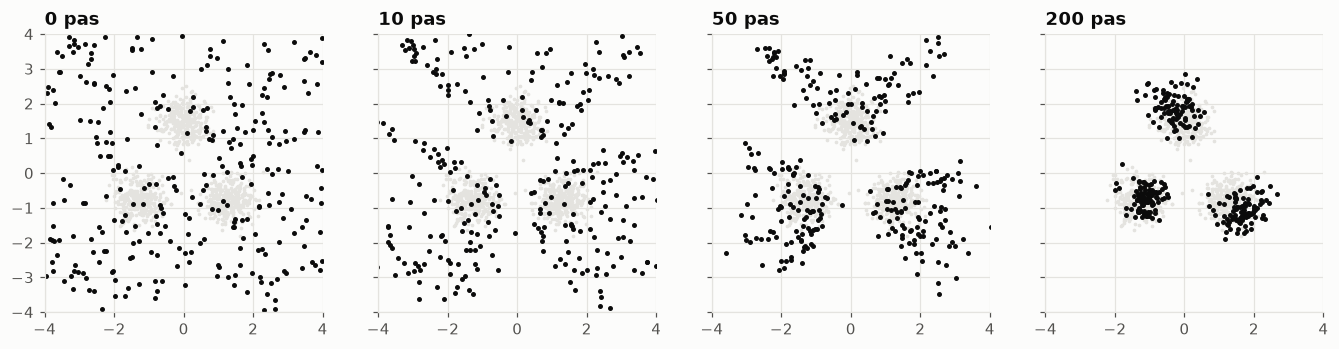

In [4]:
torch.manual_seed(1)
x_cur, done = torch.rand(300, 2) * 8 - 4, 0
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharex=True, sharey=True)
for ax, n_steps in zip(axes, [0, 10, 50, 200]):
    if n_steps > done:
        x_cur = sgld(jem_toy, x_cur, n_steps=n_steps - done, step_size=0.05, noise=0.05)
    done = n_steps
    ax.scatter(x_toy[:, 0], x_toy[:, 1], s=2, color="#e4e3df")
    ax.scatter(x_cur[:, 0].numpy(), x_cur[:, 1].numpy(), s=5, color="#0b0b0b")
    ax.set_title(f"{n_steps} pas"); ax.set_xlim(-4, 4); ax.set_ylim(-4, 4); ax.set_aspect("equal")
plt.show()

## 3. Choix de `alpha` sur la validation

Critères mesurés sur 2025 uniquement : NLL de validation à l'époque retenue, et AUROC de détection des **bugs de bots créés en 2025** par l'énergie. Les bots et bugs de 2026 sont réservés au test (`train.bots_of_period`). Ces runs sont journalisés dans MLflow sans sérialiser le modèle.

In [5]:
from jem_prioriser.train import TrainConfig, train

def selected_epoch(history, cfg):
    rows = [r for r in history if cfg.alpha == 0 or r["epoch"] > cfg.warmup_epochs]
    return min(rows, key=lambda r: r["val_nll"])

sweep = []
for alpha in [0.0, 0.1, 0.3, 1.0, 3.0]:
    cfg = TrainConfig(alpha=alpha)
    res = train(cfg, data, run_name=f"sweep-alpha{alpha}", log_model=False, verbose=False)
    best = selected_epoch(res.history, cfg)
    sweep.append({"alpha": alpha, "époque": best["epoch"], "val_nll": best["val_nll"], "val_accuracy": best["val_accuracy"],
                  "val_ece": best["val_ece"], "val_ood_auroc": best["val_ood_auroc_energy"],
                  "s/époque": np.mean([r["seconds"] for r in res.history])})
sweep = pd.DataFrame(sweep)
sweep.round(3)

,alpha,époque,val_nll,val_accuracy,val_ece,val_ood_auroc,s/époque
0,0.0,2,1.134,0.525,0.022,0.246,0.346
1,0.1,3,1.129,0.516,0.028,0.581,4.419
2,0.3,4,1.129,0.525,0.029,0.669,4.590
3,1.0,5,1.127,0.529,0.021,0.771,4.833
4,3.0,6,1.140,0.510,0.031,0.683,4.536


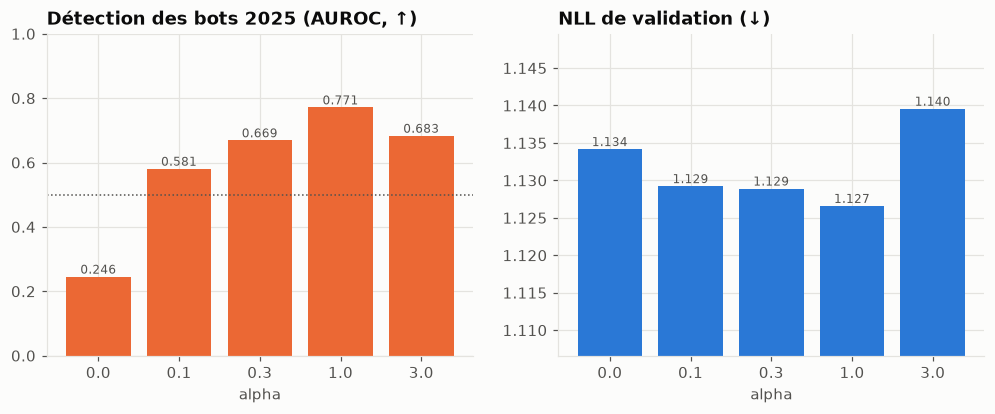

alpha retenu : 1.0


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
labels = [str(a) for a in sweep.alpha]
axes[0].bar(labels, sweep.val_ood_auroc, color=SERIES[1])
axes[0].axhline(0.5, color="#52514e", linestyle=":", linewidth=1)
axes[0].set_title("Détection des bots 2025 (AUROC, ↑)"); axes[0].set_xlabel("alpha"); axes[0].set_ylim(0, 1)
axes[1].bar(labels, sweep.val_nll, color=SERIES[0])
axes[1].set_ylim(sweep.val_nll.min() - 0.02, sweep.val_nll.max() + 0.01)
axes[1].set_title("NLL de validation (↓)"); axes[1].set_xlabel("alpha")
for ax, col in [(axes[0], "val_ood_auroc"), (axes[1], "val_nll")]:
    for i, v in enumerate(sweep[col]):
        ax.text(i, v, f"{v:.3f}", ha="center", va="bottom", fontsize=8, color="#52514e")
plt.show()

# Règle fixée avant l'évaluation : meilleure détection sans dégrader la NLL de plus de 0,01
base_nll = sweep.loc[sweep.alpha == 0, "val_nll"].item()
ok = sweep[(sweep.alpha > 0) & (sweep.val_nll <= base_nll + 0.01)]
best_alpha = float(ok.loc[ok.val_ood_auroc.idxmax(), "alpha"])
print(f"alpha retenu : {best_alpha}")

- La détection croît avec `alpha` jusqu'à 1, puis le terme génératif prend le pas sur la classification (`alpha = 3` : NLL dégradée).
- À `alpha = 1`, la NLL de validation est **meilleure** que celle du classifieur, et la meilleure époque arrive plus tard (5 au lieu de 2) : le terme génératif agit comme un régularisateur qui limite la croissance des logits.
- Coût : ~4,5 s par époque contre 0,35 s, soit ~13 fois plus.

## 4. Entraînement final

In [7]:
jem = train(TrainConfig(alpha=best_alpha), data, run_name="jem")

[ 1/20] ce=1.159 | val acc=0.511 f1=0.445 nll=1.141 ece=0.020 ood=0.28 (0.4s)


[ 2/20] ce=1.027 | val acc=0.523 f1=0.473 nll=1.135 ece=0.019 ood=0.26 (0.3s)


[ 3/20] ce=1.117 gen=+0.505 | val acc=0.501 f1=0.372 nll=1.153 ece=0.036 ood=0.67 (5.6s)


[ 4/20] ce=1.021 gen=+0.068 | val acc=0.519 f1=0.445 nll=1.128 ece=0.031 ood=0.72 (6.5s)


[ 5/20] ce=0.994 gen=+0.005 | val acc=0.529 f1=0.464 nll=1.127 ece=0.022 ood=0.77 (6.5s)


...

[16/20] ce=0.897 gen=-0.066 | val acc=0.514 f1=0.453 nll=1.166 ece=0.046 ood=0.57 (5.1s)


[17/20] ce=0.884 gen=-0.082 | val acc=0.527 f1=0.464 nll=1.164 ece=0.038 ood=0.58 (4.8s)


[18/20] ce=0.870 gen=-0.081 | val acc=0.526 f1=0.468 nll=1.163 ece=0.038 ood=0.75 (4.8s)


[19/20] ce=0.855 gen=-0.095 | val acc=0.526 f1=0.467 nll=1.176 ece=0.036 ood=0.62 (4.6s)


[20/20] ce=0.838 gen=-0.104 | val acc=0.530 f1=0.468 nll=1.180 ece=0.039 ood=0.68 (4.7s)


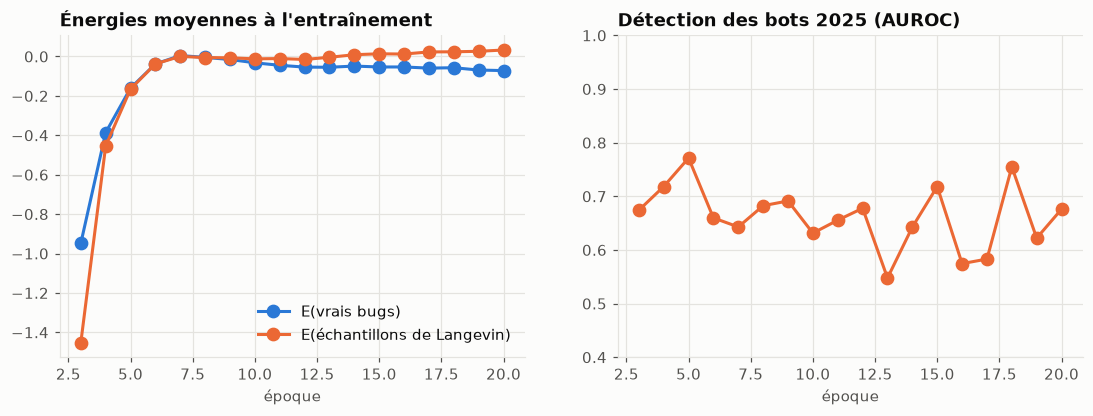

In [8]:
h = pd.DataFrame(jem.history)
h = h[h.epoch > TrainConfig().warmup_epochs]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(h.epoch, h.train_e_pos, marker="o", label="E(vrais bugs)")
axes[0].plot(h.epoch, h.train_e_neg, marker="o", label="E(échantillons de Langevin)")
axes[0].set_title("Énergies moyennes à l'entraînement"); axes[0].set_xlabel("époque"); axes[0].legend()
axes[1].plot(h.epoch, h.val_ood_auroc_energy, marker="o", color=SERIES[1])
axes[1].set_title("Détection des bots 2025 (AUROC)"); axes[1].set_xlabel("époque"); axes[1].set_ylim(0.4, 1)
plt.show()

- Les énergies des données et des échantillons restent proches et bornées : l'entraînement est stable, sans divergence.
- La détection apparaît dès la première époque générative (0,67) mais **fluctue** ensuite entre 0,55 et 0,77 : l'échantillonnage de Langevin est bruité et le paysage d'énergie évolue à chaque itération. Sa variabilité est mesurée sur plusieurs graines au notebook 04.